## **TUGAS MODUL 1 OPEN RECRUITMENT MCI**
---
KELOMPOK 11
 1. Nasyita Larasati E. - 5025241201
 2. Rahma Sakinah - 5025241222
---

In [ ]:
import sys
!"{sys.executable}" -m pip install pandas numpy matplotlib pyspark==3.5.1 nltk langdetect contractions wordcloud scikit-learn

     ---------------------------------------- 0.0/52.8 kB ? eta -:--:--
     ---------------------- --------------- 30.7/52.8 kB 640.0 kB/s eta 0:00:01
     ---------------------- --------------- 30.7/52.8 kB 640.0 kB/s eta 0:00:01
     ---------------------- --------------- 30.7/52.8 kB 640.0 kB/s eta 0:00:01
     ---------------------- --------------- 30.7/52.8 kB 640.0 kB/s eta 0:00:01
     ----------------------------- -------- 41.0/52.8 kB 150.6 kB/s eta 0:00:01
     -------------------------------------- 52.8/52.8 kB 170.4 kB/s eta 0:00:00
  Using cached pyspark-3.5.1.tar.gz (317.0 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached nltk-3.9.4-py3-none-any.whl.metadata (3.2 kB)
  Using ca


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import sys
print(sys.executable)

import pyspark
print(pyspark.__version__)

c:\Users\LEGION\AppData\Local\Programs\Python\Python311\python.exe
3.5.1


In [ ]:
import sys
!"{sys.executable}" -m pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)



[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = pd.read_csv(r"D:\PROJECT MCI\MODUL 1\steam_game_reviews.csv")

C:\Users\LEGION\AppData\Local\Temp\ipykernel_38392\3694280917.py:1: DtypeWarning: Columns (0: helpful, 1: funny) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(r"D:\PROJECT MCI\MODUL 1\steam_game_reviews.csv")


# **Eksplorasi Dataset (EDA)**
---

In [ ]:
# Tampilkan nama kolom
print(data.shape)

(992153, 8)


In [ ]:
# Tampilkan nama kolom
for col in data.columns:
    print(col)

review
hours_played
helpful
funny
recommendation
date
game_name
username


In [ ]:
# Tampilkan informasi tentang dataset
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 992153 entries, 0 to 992152
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   review          991650 non-null  str   
 1   hours_played    992153 non-null  str   
 2   helpful         992153 non-null  object
 3   funny           992153 non-null  object
 4   recommendation  992153 non-null  str   
 5   date            992153 non-null  str   
 6   game_name       992153 non-null  str   
 7   username        992072 non-null  str   
dtypes: object(2), str(6)
memory usage: 60.6+ MB


In [ ]:
# Tampilkan statistik deskriptif untuk kolom numerik
data.describe()

,review,hours_played,helpful,funny,recommendation,date,game_name,username
count,991650,992153,992153,992153,992153,992153,992153,992072
unique,909736,44229,2729,1775,2,6147,242,765581
top,good,0.2,1,0,Recommended,"November 22, 2023",Grand Theft Auto V,123
freq,1111,3305,255234,735925,805782,3048,5010,161


In [ ]:
# Tampilkan beberapa baris pertama dari dataset
data.head()

,review,hours_played,helpful,funny,recommendation,date,game_name,username
0,The game itself is also super fun. The PvP and...,39.9,"1,152",13,Recommended,14 September,"Warhammer 40,000: Space Marine 2",Sentinowl\n224 products in account
1,Never cared much about Warhammer until this ga...,91.5,712,116,Recommended,13 September,"Warhammer 40,000: Space Marine 2",userpig\n248 products in account
2,A salute to all the fallen battle brothers who...,43.3,492,33,Recommended,14 September,"Warhammer 40,000: Space Marine 2",Imparat0r\n112 products in account
3,this game feels like it was made in the mid 20...,16.8,661,15,Recommended,14 September,"Warhammer 40,000: Space Marine 2",Fattest_falcon
4,Reminds me of something I've lost. A genuine g...,24.0,557,4,Recommended,12 September,"Warhammer 40,000: Space Marine 2",Jek\n410 products in account


# yang ini explorasi & cleaning setelah dicut 3 kolom


In [ ]:
# Pilih kolom yang relevan untuk analisis
selected_columns = ['game_name', 'username', 'review']
df_selected = data[selected_columns].copy()

In [ ]:
# Tampilkan bentuk dataset setelah memilih kolom
print(df_selected.shape)

(992153, 3)


In [ ]:
# Tampilkan nama kolom setelah memilih kolom
for col in df_selected.columns:
    print(col)

game_name
username
review


In [ ]:
# Tampilkan informasi tentang dataset setelah memilih kolom
df_selected.info()

<class 'pandas.DataFrame'>
RangeIndex: 992153 entries, 0 to 992152
Data columns (total 3 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   game_name  992153 non-null  str  
 1   username   992072 non-null  str  
 2   review     991650 non-null  str  
dtypes: str(3)
memory usage: 22.7 MB


In [ ]:
# Tampilkan statistik deskriptif untuk kolom numerik setelah memilih kolom
df_selected.describe()

,game_name,username,review
count,992153,992072,991650
unique,242,765581,909736
top,Grand Theft Auto V,123,good
freq,5010,161,1111


In [ ]:
# Tampilkan beberapa baris pertama dari dataset setelah memilih kolom
df_selected.head()

,game_name,username,review
0,"Warhammer 40,000: Space Marine 2",Sentinowl\n224 products in account,The game itself is also super fun. The PvP and...
1,"Warhammer 40,000: Space Marine 2",userpig\n248 products in account,Never cared much about Warhammer until this ga...
2,"Warhammer 40,000: Space Marine 2",Imparat0r\n112 products in account,A salute to all the fallen battle brothers who...
3,"Warhammer 40,000: Space Marine 2",Fattest_falcon,this game feels like it was made in the mid 20...
4,"Warhammer 40,000: Space Marine 2",Jek\n410 products in account,Reminds me of something I've lost. A genuine g...


In [ ]:
# Tampilkan jumlah nilai duplikat dalam dataset setelah memilih kolom
print(df_selected.duplicated().sum())

3


In [ ]:
# Tampilkan baris yang duplikat dalam dataset setelah memilih kolom
display(df_selected[df_selected.duplicated(keep=False)])

,game_name,username,review
242762,Satisfactory,howsit,Gameplay 10/10UI and graphics 10/10Re-playabil...
242781,Satisfactory,howsit,Gameplay 10/10UI and graphics 10/10Re-playabil...
399084,Don't Starve,Leefordicus Maximus,"2014 Very addictive, fun survival game. Love t..."
400881,Don't Starve,Leefordicus Maximus,"2014 Very addictive, fun survival game. Love t..."
929163,DiRT Rally 2.0,Wyatt,2022
929834,DiRT Rally 2.0,Wyatt,2022


In [ ]:
# Hapus duplikat dari dataset
df_selected = df_selected.drop_duplicates()

print("Jumlah duplikat setelah dihapus:", df_selected.duplicated().sum())

Jumlah duplikat setelah dihapus: 0


In [ ]:
# Dataset yang memiliki data null 
print(df_selected.isnull().sum())

game_name      0
username      81
review       503
dtype: int64


In [ ]:
# Hapus baris yang memiliki nilai null pada kolom 'review' dan 'username'
df_selected.dropna(subset=['review', 'username'], inplace=True)

print("Jumlah nilai null setelah penghapusan:")
print(df_selected.isnull().sum())
print(f"Ukuran dataset setelah penghapusan: {df_selected.shape[0]} baris dan {df_selected.shape[1]} kolom")

Jumlah nilai null setelah penghapusan:
game_name    0
username     0
review       0
dtype: int64
Ukuran dataset setelah penghapusan: 991566 baris dan 3 kolom


In [ ]:
# Tampilkan jumlah nilai unik dalam kolom 'game_name' dan frekuensi kemunculan setiap game
print(df_selected['game_name'].nunique())
print(df_selected['game_name'].value_counts().head(10))

242
game_name
Warframe                           5010
Call of Duty®                      5010
Tom Clancy's Rainbow Six® Siege    5010
Wallpaper Engine                   5010
FINAL FANTASY XIV Online           5010
Team Fortress 2                    5010
Left 4 Dead 2                      5010
Hollow Knight                      5010
Unturned                           5010
Valheim                            5010
Name: count, dtype: int64


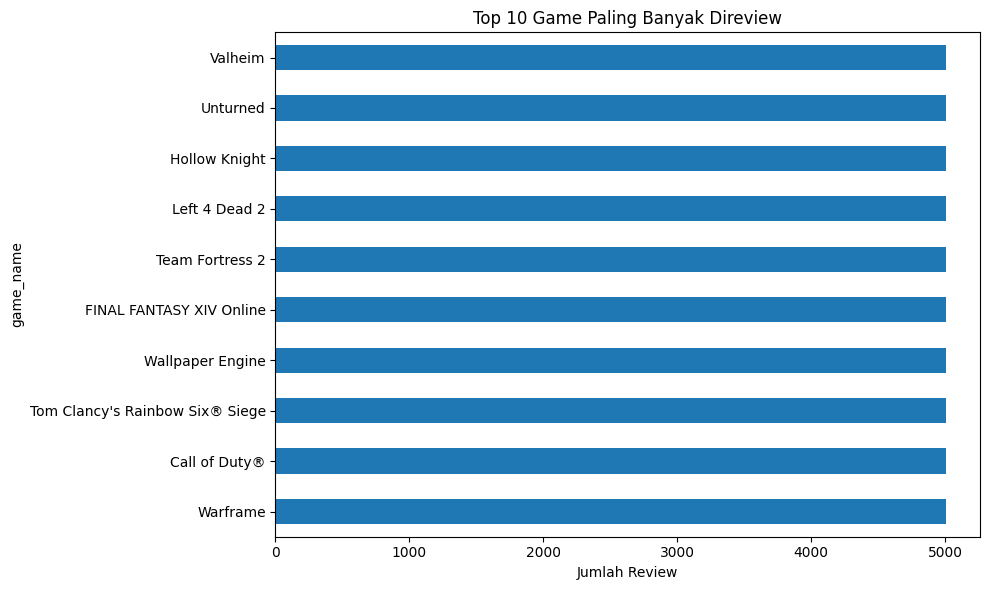

In [ ]:
import matplotlib.pyplot as plt

# Visualisasikan 10 game yang paling banyak direview
df_selected['game_name'].value_counts().head(10).plot(kind='barh', figsize=(10,6))
plt.title('Top 10 Game Paling Banyak Direview')
plt.xlabel('Jumlah Review')
plt.tight_layout()
plt.show()

In [ ]:
# Tampilkan beberapa review acak dari dataset setelah pembersihan
print(df_selected['review'].sample(5).values)

<StringArray>
[                                                                                                                                                          'After playing Baldur's Gate 3 for 130+ hours, it's fun to play a game where you can just beat up a bunch of mobs over and over, level up, and get new gear and skills. A great game to jump in and out of.',
                                                                                                                                                                                                                                                                                                                                                  'I've lost my sanity',
 '2016 Product received for free Early Access Review Amazing open world, lots of interactions and build possibilities.The lore is very innovative and well thought.The mechanics are very flexible, but unforgiving.There are some instabilities due to the fact that th

In [ ]:
!pip install contractions

import contractions

# Fungsi untuk memperluas kontraksi dalam teks
def expand_contractions(text):
    try:
        if isinstance(text, str) and len(text) > 0:
            return contractions.fix(text)
        return text
    except:
        return text

df_selected['review'] = df_selected['review'].apply(expand_contractions)

print("Contoh setelah expand contractions:")
display(df_selected[['review']].sample(5))


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Contoh setelah expand contractions:


,review
226538,2022 Early Access Review bought for the price ...
479489,"2022 Several possibilities when deck building,..."
708510,2020 KILLING IS MY BUSINESS... AND BUSINESS IS...
152388,2018 good
104218,2022 This game is for those who could not affo...


In [ ]:
import re

# Fungsi untuk membersihkan teks review
def clean_text(text):
    text = text.lower()                           # Lowercase
    text = re.sub(r'http\S+|www\S+', '', text)    # Hapus URL
    text = re.sub(r'\d+', '', text)               # Hapus angka
    text = re.sub(r'[\W_]+', ' ', text)           # Hapus punctuation
    text = re.sub(r'\b\w\b', '', text)            # Hapus single character
    text = re.sub(r'(.)\1{2,}', r'\1', text)      # Hapus repeated chars
    text = re.sub(r'\s+', ' ', text).strip()      # Hapus extra whitespace
    return text

df_selected['review_cleaned'] = df_selected['review'].apply(clean_text)

# Get a sample of the DataFrame for comparison
sample_df = df_selected.sample(5)

print("Original Review Sample:")
for i, row in sample_df.iterrows():
    print(f"- {row['review']}")

print("\nCleaned Review Sample:")
for i, row in sample_df.iterrows():
    print(f"- {row['review_cleaned']}")

Original Review Sample:
- 2021 You Sunk My Battleship!
- 2023 cool
- 2020 Early Access Review Currently - the game severly lacks any new features comapred to Warband. Not sure what creators were doing all that time.
- 2022 after the update its actually KIND OF enjoyable. I have to admit its a step in the RIGHT direction. And its free
- 2022 Extremely fun and rage inducing game with friends!

Cleaned Review Sample:
- you sunk my battleship
- cool
- early access review currently the game severly lacks any new features comapred to warband not sure what creators were doing all that time
- after the update its actually kind of enjoyable have to admit its step in the right direction and its free
- extremely fun and rage inducing game with friends


In [ ]:
# Tampilkan beberapa review acak dari dataset setelah pembersihan
display(df_selected[['review', 'review_cleaned']].sample(5))

,review,review_cleaned
687630,i edge to this game,edge to this game
198903,2016 Early Access Review Really fun in singlep...,early access review really fun in singleplayer...
781976,2023 Acts one and two are great. And the comba...,acts one and two are great and the combat is p...
949133,2022 hi,hi
53369,2023 Do not buy this game simple as that,do not buy this game simple as that


In [ ]:
!pip install langdetect


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# Fungsi untuk mendeteksi bahasa dalam teks
df_sample = df_selected.sample(n=50000, random_state=42).reset_index(drop=True)
print(df_sample.shape)

(50000, 4)


In [ ]:
# Tampilkan beberapa baris pertama dari sample dataset
print(df_sample.shape)

(50000, 4)


In [ ]:
# Fungsi untuk mendeteksi bahasa dalam teks
from langdetect import detect, LangDetectException

def detect_language(text):
    try:
        return detect(text)
    except LangDetectException:
        return 'unknown'

df_sample['language'] = df_sample['review_cleaned'].apply(detect_language)

# Lihat distribusi
print(df_sample['language'].value_counts())
print(f"\nTotal: {len(df_sample)} baris")
print(f"English: {(df_sample['language'] == 'en').sum()} baris ({(df_sample['language'] == 'en').mean()*100:.1f}%)")
print(f"Non-English: {(df_sample['language'] != 'en').sum()} baris ({(df_sample['language'] != 'en').mean()*100:.1f}%)")

language
en         42324
so           956
unknown      703
af           614
cy           419
tl           389
no           363
da           361
tr           360
es           333
pl           316
ro           275
it           235
nl           189
ca           188
sl           183
fr           179
fi           162
et           159
pt           153
id           143
sw           123
sq           122
hr            89
sv            83
ru            82
sk            75
de            62
lt            61
cs            50
lv            47
hu            46
zh-cn         44
ar            25
vi            24
ko            13
bg            12
th            10
ja             7
mk             7
fa             5
zh-tw          4
uk             3
he             1
ur             1
Name: count, dtype: int64

Total: 50000 baris
English: 42324 baris (84.6%)
Non-English: 7676 baris (15.4%)


In [ ]:
from langdetect import detect, LangDetectException
from multiprocessing.pool import ThreadPool

# Fungsi untuk mendeteksi bahasa dalam teks
def detect_language(text):
    try:
        return detect(text)
    except LangDetectException:
        return 'unknown'

# Gunakan ThreadPool untuk mempercepat deteksi bahasa
with ThreadPool(12) as pool:
    df_selected['language'] = pool.map(detect_language, df_selected['review_cleaned'])

# Hapus non-English
df_selected = df_selected[df_selected['language'] == 'en'].drop(columns=['language'])
print(f"Sesudah hapus non-English: {df_selected.shape}")

Sesudah hapus non-English: (841307, 4)


In [ ]:
# Fungsi untuk mendeteksi bahasa dalam teks
df_sample = df_selected.sample(n=50000, random_state=42).reset_index(drop=True)
print(df_sample.shape)

(50000, 4)


In [ ]:
# Tampilkan beberapa baris pertama dari sample dataset
print(df_sample.shape)

(50000, 4)


In [ ]:
from langdetect import detect, LangDetectException

# Fungsi untuk mendeteksi bahasa dalam teks
def detect_language(text):
    try:
        return detect(text)
    except LangDetectException:
        return 'unknown'

df_sample['language'] = df_sample['review_cleaned'].apply(detect_language)

# Lihat distribusi
print(df_sample['language'].value_counts())
print(f"\nTotal: {len(df_sample)} baris")
print(f"English: {(df_sample['language'] == 'en').sum()} baris ({(df_sample['language'] == 'en').mean()*100:.1f}%)")
print(f"Non-English: {(df_sample['language'] != 'en').sum()} baris ({(df_sample['language'] != 'en').mean()*100:.1f}%)")

language
en    49721
af       39
da       29
no       23
cy       22
so       20
it       19
nl       17
fr       15
sq       12
tl       11
es       10
ca        9
sv        8
et        8
ro        6
id        4
sk        4
sl        3
pt        3
de        2
cs        2
pl        2
hr        2
tr        2
hu        2
lt        1
vi        1
fi        1
lv        1
bg        1
Name: count, dtype: int64

Total: 50000 baris
English: 49721 baris (99.4%)
Non-English: 279 baris (0.6%)


In [ ]:
import nltk
from nltk import pos_tag
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
from multiprocessing.pool import ThreadPool

nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger_eng')

lemmatizer = WordNetLemmatizer()

# Fungsi mendapatkan POS tag yang sesuai untuk lemmatization
def get_wordnet_pos(tag):
    if tag.startswith('J'): return wordnet.ADJ
    elif tag.startswith('V'): return wordnet.VERB
    elif tag.startswith('N'): return wordnet.NOUN
    elif tag.startswith('R'): return wordnet.ADV
    else: return wordnet.NOUN

# Fungsi untuk lemmatization teks
def lemmatize_text(text):
    words = text.split()
    pos_tags = pos_tag(words)
    return ' '.join([lemmatizer.lemmatize(w, get_wordnet_pos(t)) for w, t in pos_tags])

with ThreadPool(12) as pool:
    df_selected['review_cleaned'] = pool.map(lemmatize_text, df_selected['review_cleaned'])

# Verifikasi
print("Contoh hasil lemmatization:")
display(df_selected[['review', 'review_cleaned']].sample(5))

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\LEGION\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\LEGION\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


Contoh hasil lemmatization:


,review,review_cleaned
649715,2016 After 5k Hours across 3 accounts. It is t...,after hour across account it be time to write ...
633078,2019 i love this game. cheap price for lots of...,love this game cheap price for lot of fun you ...
861481,"2020 Great port from the tabletop, streamlines...",great port from the tabletop streamlines so ma...
593829,"2023 Update: Well, they did release patches, n...",update well they do release patch now my rtx c...
654279,2020 Pure chaos with charming little minions.,pure chaos with charm little minion



[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


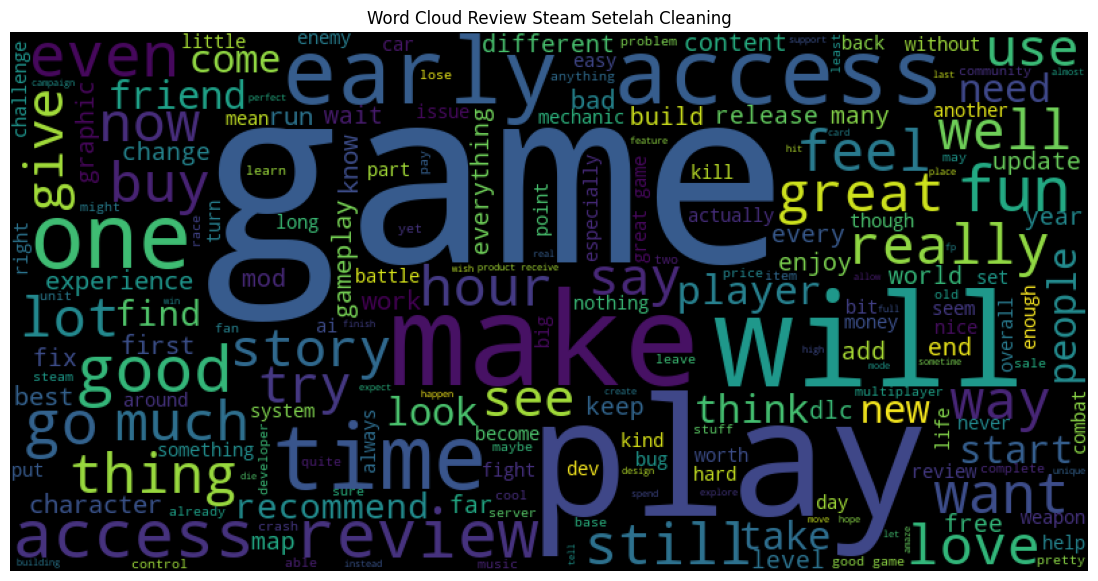

In [ ]:
!pip install wordcloud

from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Visualisasikan word cloud dari review yang sudah dibersihkan
text = ' '.join(df_selected['review_cleaned'].sample(10000))
wc = WordCloud(width=800, height=400, background_color='black').generate(text)
plt.figure(figsize=(15,7))
plt.imshow(wc)
plt.axis('off')
plt.title('Word Cloud Review Steam Setelah Cleaning')
plt.show()

In [ ]:
# Simpan dataset yang sudah dibersihkan ke file CSV
df_selected.to_csv(r"D:\PROJECT MCI\MODUL 1\df_selected_cleaned.csv", index=False)
print("Export selesai!")

Export selesai!


----------------------------------------
Exception occurred during processing of request from ('127.0.0.1', 63624)
Traceback (most recent call last):
  File "c:\Users\LEGION\AppData\Local\Programs\Python\Python311\Lib\socketserver.py", line 317, in _handle_request_noblock
    self.process_request(request, client_address)
  File "c:\Users\LEGION\AppData\Local\Programs\Python\Python311\Lib\socketserver.py", line 348, in process_request
    self.finish_request(request, client_address)
  File "c:\Users\LEGION\AppData\Local\Programs\Python\Python311\Lib\socketserver.py", line 361, in finish_request
    self.RequestHandlerClass(request, client_address, self)
  File "c:\Users\LEGION\AppData\Local\Programs\Python\Python311\Lib\socketserver.py", line 755, in __init__
    self.handle()
  File "c:\Users\LEGION\AppData\Local\Programs\Python\Python311\Lib\site-packages\pyspark\accumulators.py", line 295, in handle
    poll(accum_updates)
  File "c:\Users\LEGION\AppData\Local\Programs\Python\Python3